# Online Store Sales Data Analytics Project

## Part 1 – Data Loading

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_excel("data/sales_data_2000_rows (2).xlsx")

In [4]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 173.7 KB


In [6]:
df.shape

(2000, 7)

In [7]:
df.columns

Index(['Order_ID', 'Date', 'Product', 'Category', 'City', 'Quantity', 'Price'],
      dtype='str')

In [8]:
df.describe()

,Order_ID,Quantity,Price
count,2000.000000,1999.000000,2000.00000
mean,2000.500000,3.036018,8293.60150
std,577.494589,1.415877,14462.36937
min,1001.000000,1.000000,-73.00000
25%,1500.750000,2.000000,495.75000
50%,2000.500000,3.000000,1487.00000
75%,2500.250000,4.000000,8765.50000
max,3000.000000,5.000000,55297.00000


## Part 2 – Data Cleaning

In [9]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

In [10]:
df.isnull().sum().sum()

np.int64(1)

In [11]:
df[df.isnull().any(axis=1)]

,Order_ID,Date,Product,Category,City,Quantity,Price
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [12]:
df[df["Quantity"].isnull()]

,Order_ID,Date,Product,Category,City,Quantity,Price
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [13]:
df = df.dropna(subset=["Quantity"])

In [14]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df[df.duplicated()]

,Order_ID,Date,Product,Category,City,Quantity,Price


In [17]:
df = df.drop_duplicates()

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df["Product"].unique()

<ArrowStringArray>
[ 'Printer',      'Pen',    'Mouse',    'Chair', 'Notebook',    'Table',
   'Laptop',      'Bag', 'Keyboard',     'Sofa',  'Monitor',   'Bottle']
Length: 12, dtype: str

In [20]:
df["Category"].unique()

<ArrowStringArray>
['Electronics', 'Stationery', 'Furniture', 'Accessories']
Length: 4, dtype: str

In [21]:
df["City"].unique()

<ArrowStringArray>
[  'Kolkata', 'Hyderabad',   'Chennai', 'Ahmedabad',    'Mumbai',      'Pune',
 'Bangalore',     'Delhi']
Length: 8, dtype: str

In [22]:
df["Product"] = df["Product"].str.strip()
df["Category"] = df["Category"].str.strip()
df["City"] = df["City"].str.strip()

In [23]:
df["Date"].dtype

<StringDtype(na_value=nan)>

In [24]:
df["Date"] = pd.to_datetime(df["Date"])

In [25]:
df["Date"].dtype

dtype('<M8[us]')

In [26]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
5,1006,2025-10-20,Notebook,Stationery,Ahmedabad,4.0,244


## Part 3 – Data Processing

In [27]:
df["Revenue"] = df["Quantity"] * df["Price"]

In [28]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
5,1006,2025-10-20,Notebook,Stationery,Ahmedabad,4.0,244,976.0


In [29]:
df[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,3.0,9591,28773.0
1,5.0,318,1590.0
2,1.0,697,697.0
3,1.0,3410,3410.0
5,4.0,244,976.0


In [30]:
df["Revenue"].dtype

dtype('float64')

## Part 4 – Data Analysis

### Task 1 – Total Revenue

In [31]:
total_revenue = df["Revenue"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 51500062.0


### Task 2 – Best Selling Product

In [32]:
best_selling_product = df.groupby("Product")["Quantity"].sum().idxmax()

print("Best Selling Product:", best_selling_product)

Best Selling Product: Chair


### Task 3 – Best Performing City

In [33]:
best_performing_city = df.groupby("City")["Revenue"].sum().idxmax()

print("Best Performing City:", best_performing_city)

Best Performing City: Ahmedabad


### Task 4 – Category Analysis

In [34]:
category_revenue = df.groupby("Category")["Revenue"].sum()

print(category_revenue)

Category
Accessories      905769.0
Electronics    37093350.0
Furniture      13343784.0
Stationery       157159.0
Name: Revenue, dtype: float64


### Task 5 – Monthly Sales Analysis

In [35]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Revenue"].sum()

print(monthly_sales)

Date
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


### Task 6 – Top 3 Products by Revenue

In [36]:
top_3_products = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False).head(3)

print(top_3_products)

Product
Laptop     27105144.0
Sofa        8106368.0
Printer     4966315.0
Name: Revenue, dtype: float64


### Task 7 – Average Order Value

In [37]:
average_order_value = df.groupby("Order_ID")["Revenue"].sum().mean()

print("Average Order Value:", average_order_value)

Average Order Value: 25762.912456228114


### Summary of Data Analysis

The sales dataset was analyzed to identify total revenue, best-selling products, top-performing cities, category-wise revenue, and monthly sales trends. Additional analysis was performed to identify the top three products by revenue and average order value.

## Part 5 – Data Visualization

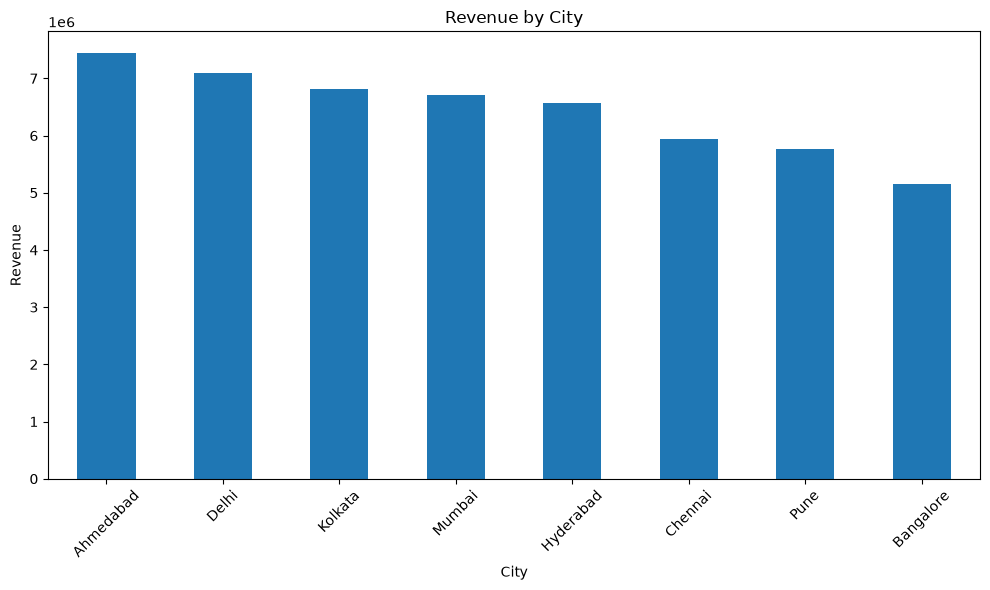

In [41]:
city_revenue = df.groupby("City")["Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
city_revenue.plot(kind="bar")

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("charts/revenue_by_city.png", bbox_inches="tight")
plt.show()

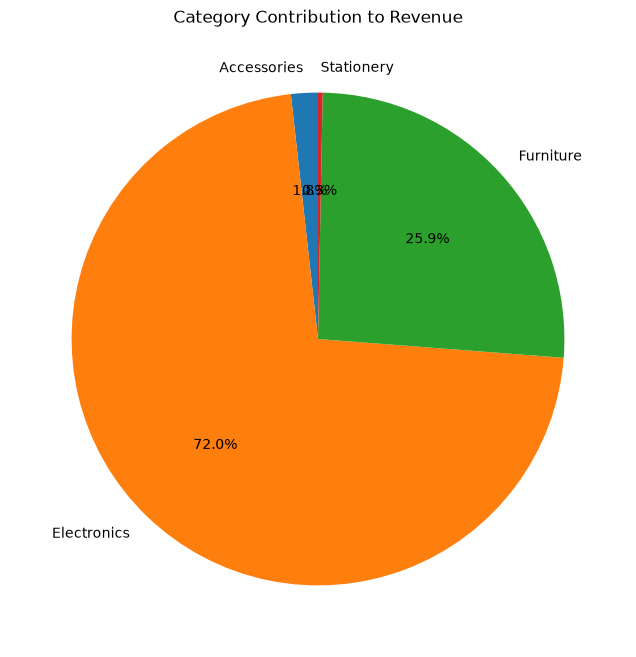

In [42]:
category_revenue = df.groupby("Category")["Revenue"].sum()

plt.figure(figsize=(8, 8))
plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category Contribution to Revenue")
plt.savefig("charts/category_contribution.png", bbox_inches="tight")
plt.show()

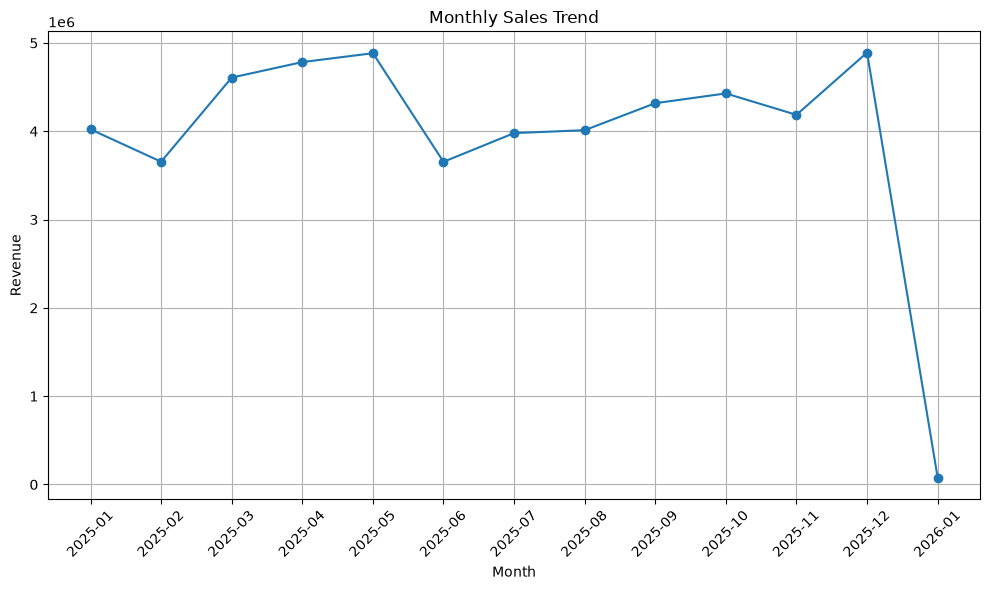

In [43]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Revenue"].sum()

plt.figure(figsize=(10, 6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.savefig("charts/monthly_sales_trend.png", bbox_inches="tight")
plt.show()

## Part 6 – Business Insights

In [44]:
print("Total Revenue:", total_revenue)
print("Best Selling Product:", best_selling_product)
print("Best Performing City:", best_performing_city)
print("\nCategory-wise Revenue:")
print(category_revenue)
print("\nMonthly Sales:")
print(monthly_sales)
print("\nTop 3 Products by Revenue:")
print(top_3_products)
print("\nAverage Order Value:", average_order_value)

Total Revenue: 51500062.0
Best Selling Product: Chair
Best Performing City: Ahmedabad

Category-wise Revenue:
Category
Accessories      905769.0
Electronics    37093350.0
Furniture      13343784.0
Stationery       157159.0
Name: Revenue, dtype: float64

Monthly Sales:
Date
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64

Top 3 Products by Revenue:
Product
Laptop     27105144.0
Sofa        8106368.0
Printer     4966315.0
Name: Revenue, dtype: float64

Average Order Value: 25762.912456228114


### Business Insights

1. **Total Revenue:** The online store generated a total revenue of ₹5,15,00,062, indicating strong overall sales performance.

2. **Best-Selling Product:** Chair is the best-selling product based on total quantity sold, showing strong customer demand.

3. **Top-Performing City:** Ahmedabad generated the highest revenue among all cities, making it the leading sales market.

4. **Category Performance:** Electronics generated the highest revenue of ₹3,70,93,350, contributing the largest share of total sales.

5. **Top Revenue-Generating Product:** Laptop generated the highest product revenue of ₹2,71,05,144, followed by Sofa and Printer.

6. **Monthly Sales Trend:** December 2025 recorded the highest monthly revenue of ₹48,91,185. January 2026 recorded only ₹77,832, which may represent an incomplete month.

7. **Average Order Value:** The average order value was approximately ₹25,763, indicating the average revenue generated per order.

## Part 7 – Business Recommendations

### Business Recommendations

1. **Promote Best-Selling Products:** Increase the availability of popular products like Chairs to meet customer demand and improve sales.

2. **Focus on Electronics:** Since Electronics generates the highest revenue, introduce more electronic products and promotional offers to increase sales.

3. **Expand in High-Performing Cities:** Focus on Ahmedabad by offering targeted promotions and improving product availability.

4. **Improve Low-Performing Categories:** Develop marketing campaigns and discounts for Accessories and Stationery to improve their sales performance.

5. **Strengthen Monthly Sales:** Analyze seasonal sales patterns and introduce special offers during months with lower revenue to improve sales consistency.

6. **Increase Average Order Value:** Encourage customers to purchase additional products through product bundles, cross-selling, and discounts on larger orders.

In [45]:
df.to_csv("data/sales_data_cleaned.csv", index=False)